# **Tools**

- An LLM itself can only rely on its built-in knowledge
- It needs **Tools** to perform lots of tasks like:
    - Browsing the internet
    - Reading from a pdf file
    - Taking screen shots
    - Unzip a zip file

## **Architecture**

A Naive Approach:

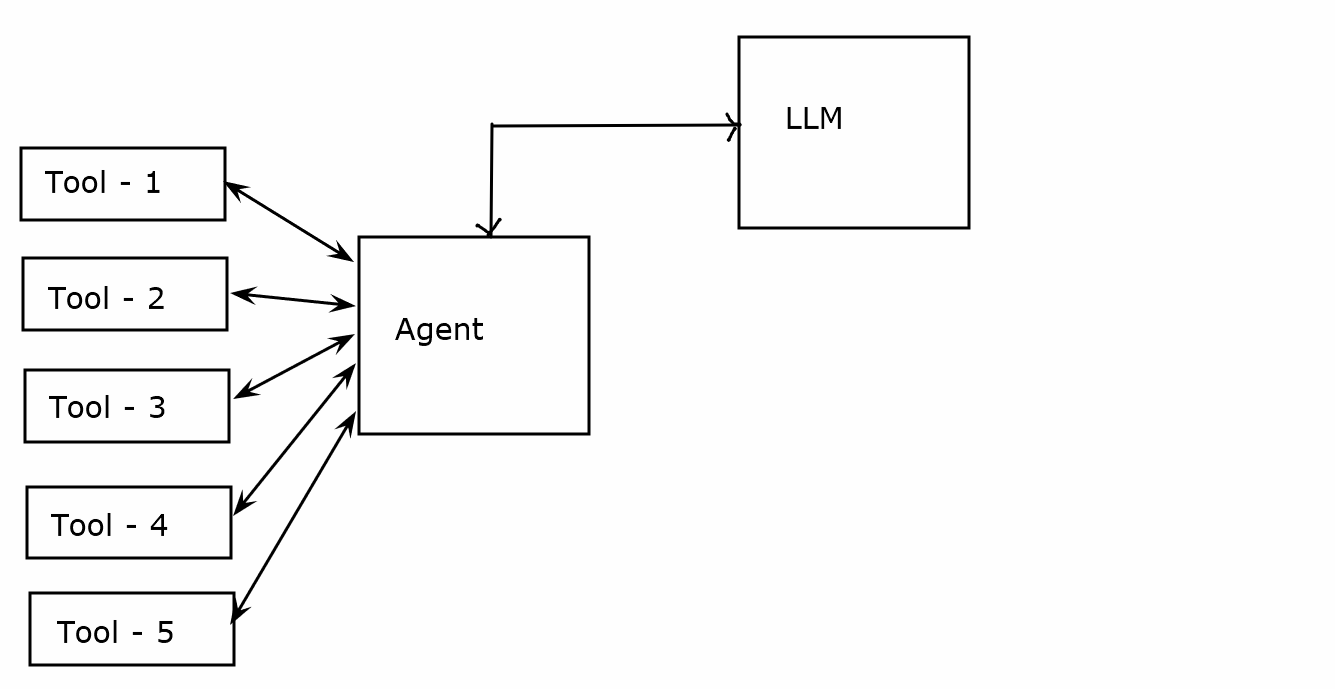

Better Approach:

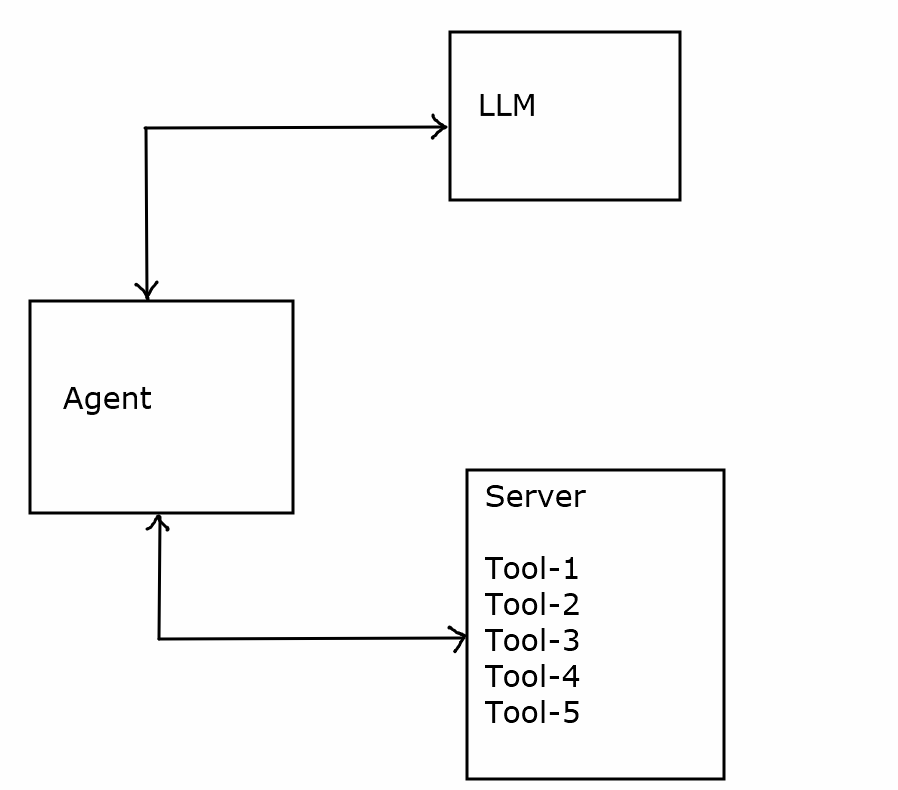

## **Communication**

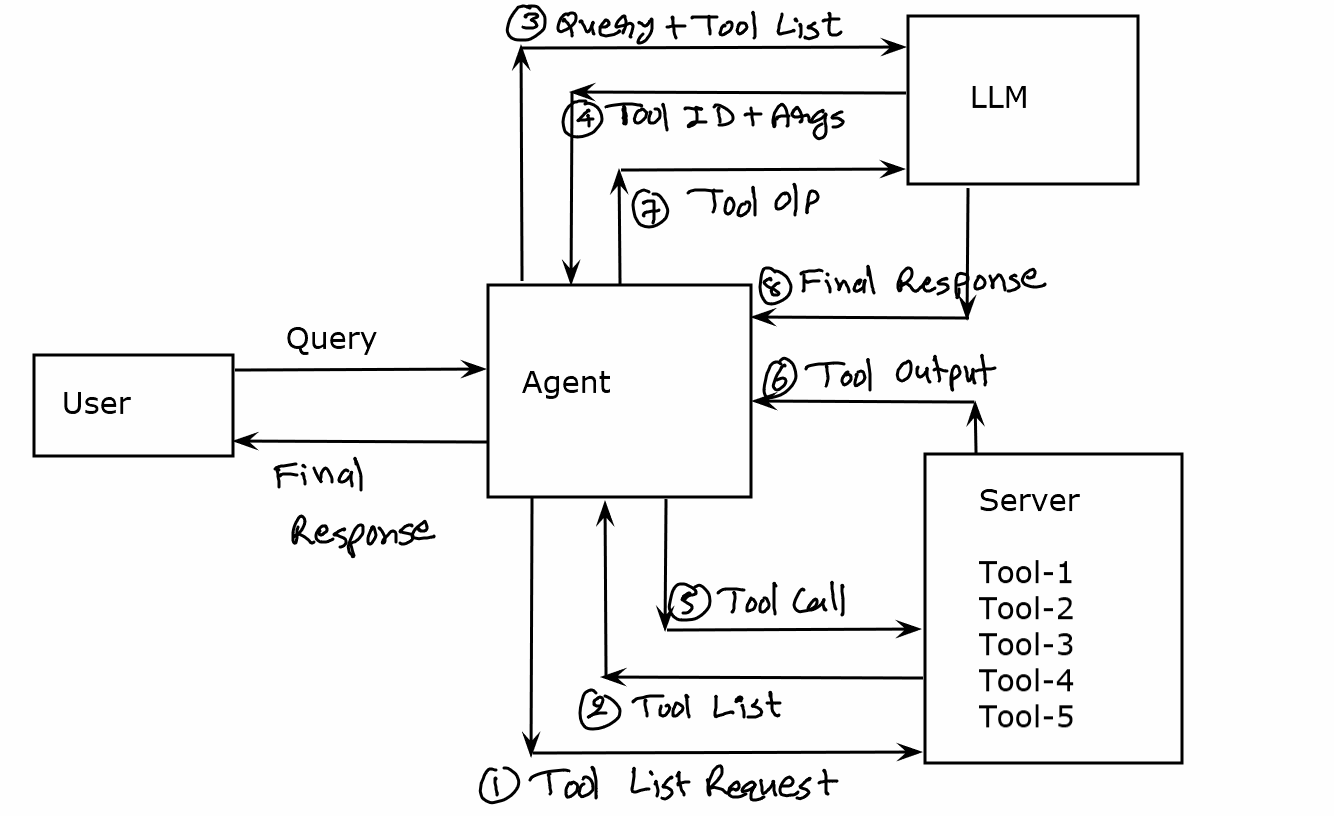

## **Example - A Simple Multi Tool Agent**

In [1]:
from openai import OpenAI
import os
from dotenv import load_dotenv

load_dotenv()
agent = OpenAI(

    base_url="https://openrouter.ai/api/v1",
    
    api_key=os.getenv("OPENROUTER_API_KEY")

)

**Python Recap**
```
eval()
try - except
```

In [72]:
# Calculator tool: add, sub, multiply, divide, floor division, power, modulo operations
inp = "30 + 20"
inp = "30 - 20"
inp = "30 ** 2"
# eval(inp)
def calculator(expression: str) -> str:
    # print(type(expression))
    try:
        return f"{expression} = {eval(expression)}"
    # except ZeroDivisionError:
    #     return "Divide by zero"
    # except:
    #     return "Something went wrong"
    
    except Exception as e:
        return e


In [73]:
# calculator("30 + 20")
# calculator(30 + 20)
# calculator("30 / 0")
# while True:
#     print("Hello World!")

calculator(30 + 20)
calculator("30/0")

ZeroDivisionError('division by zero')

### **Tools**

In [2]:
# ------------------------ Tool-1: Calculator ------------------------

def calculator(expression):
    try:
        return f"{expression} = {eval(expression)}"    
    except Exception as e:
        return e

# ------------------------ Tool-2: Text Summarizer Tool ------------------------

def summarizer(text):
    words_list = text.split()
    summary_list = words_list[:20]
    summary = " ".join(summary_list)
    return summary

# ------------------------ Tool-3: Word Counting Tool ------------------------

def count_words(text):
    words_list = text.split()
    return f"Word count: {len(words_list)}"

### Tool Definitions according to OpenAI's SDK

In [7]:
tools_list = [
    # tool-1 definition
    {
        "type" : "function",
        "function" : {
            "name" : "calculator",
            "description" : "Performs mathematical operations on the given expression",
            "parameters" : {
                "type" : "object",
                "properties" : {
                    "expression" : {
                        "type" : "string",
                        "description" : "Mathematical expression"
                    }
                },
                "required" : ["expression"]
            }
        }
    },

    # tool-2 definition
    {
        "type" : "function",
        "function" : {
            "name" : "summarizer",
            "description" : "Returns the summary of the given text",
            "parameters" : {
                "type" : "object",
                "properties" : {
                    "text" : {
                        "type" : "string",
                        "description" : "Text tobe summarized"
                    }
                },
                "required" : ["text"]
            }
        }
    },

    # tool-3 definition
    {
        "type" : "function",
        "function" : {
            "name" : "count_words",
            "description" : "Counts and returns the number of words in the given text",
            "parameters" : {
                "type" : "object",
                "properties" : {
                    "text" : {
                        "type" : "string",
                        "description" : "Text to count words of"
                    }
                },
                "required" : ["text"]
            }
        }
    }
]

### Conversation Memory

In [4]:
messages = [
    {
        "role" : "system",
        "content" : """
                    You are an intelligent AI assistant. 
                    Use tools whenever needed. 
                    Available capabilities:
                    - Mathematical calculation
                    - Text summary
                    - Word counting
                    """
    }
]

Welcome Message

In [6]:
welcome_msg = ("-" * 20) + (" Multi tool agent started ") + ("-" * 20)
print(welcome_msg.center(80))

       -------------------- Multi tool agent started --------------------       


### **Chat Loop**

In [11]:
print('\n[AI Assistant]: Ask me for any help or type "exit" to end the conversation.\n')

while True:
    user_prompt = input("[You] : ")

    if user_prompt.lower() == "exit":
        break

    messages.append({
        "role" : "user",
        "content" : user_prompt
    })

    response = agent.chat.completions.create(

        model="openrouter/free",

        messages= messages,

        tools= tools_list,

        tool_choice= "auto"
    )

    response = response.choices[0].message
    # print("Response:\n", response)

    if response.tool_calls:
        print("There is a tool call.")

        # First storing the response into the conversation memory
        messages.append(response)

        # print(response.tool_calls[0])
        tool_call = response.tool_calls[0]

        print("Tool Name:", tool_call.function.name)
        print("Tool Args:", tool_call.function.arguments)
        # print("Type of args:", type(tool_call.function.arguments))

        tool_name = tool_call.function.name

        import json
        tool_args = json.loads(tool_call.function.arguments)
        
        # print("Type of tool_args", type(tool_args))

        if tool_name == "calculator":
            result = calculator(tool_args["expression"])

        elif tool_name == "summarizer":
            result = summarizer(tool_args["text"])

        elif tool_name == "count_words":
            result = count_words(tool_args["text"])

        else:
            result = "Error: Unknown Tool"

        # print(result)

        # Storing the tool output into the conversation memory

        messages.append({
            "role" : "tool",

            "tool_call_id" : tool_call.id,

            "content" : result
        })


        # Second API call to the LLM
        final_response = agent.chat.completions.create(
        
            model="openrouter/free",
    
            messages= messages
        )

        ai_response = final_response.choices[0].message.content

    else:
        ai_response = response.content

    print("[AI Assistant] :", ai_response)


[AI Assistant]: Ask me for any help or type "exit" to end the conversation.



TypeError: Object of type TypeError is not JSON serializable